# 07 · Q2: model B stores eps partly as a readable direction in layers 2 and 3

**What this notebook shows.** Question 2: if model B knows an ant's eps, where is that knowledge inside it, and is it simple? We record B's hidden state (64 numbers per step) after each stage and ask:
1. **Linear probe**: can a straight-line readout recover eps from the hidden state? (fit on val windows, scored on test windows)
2. **Ceiling**: how well does B's *own output* track eps? A probe cannot be expected to beat this.
3. **Direction**: does "average high-eps hidden state minus average low-eps hidden state" give one axis that orders all eps?
4. **Straight line?**: do the ten per-eps average vectors lie along one line?

**Results (recorded run, test split).**
- Probe R² at step 127: 0.03 (input embedding), 0.15 (after layer 1), 0.38 (layer 2), 0.58 (layer 3). It grows with layers and with history.
- Ceiling: B's output vs true eps, corr² = 0.90. Best window-level linear probe: 0.58 (layer 3); adding squared features: 0.57.
- High-minus-low direction keeps eps 0.1 to 0.9 in perfect order at layers 2 and 3 (rank correlation 1.00); single-window correlation 0.47 (layer 2) and 0.64 (layer 3).
- The ten per-eps averages do **not** lie on one line: consecutive steps point in inconsistent directions (alignment -0.35 to 0.16).

**Conclusion.** eps is partly linearly readable in the middle and late layers, in the right order, which is enough to build steering vectors (notebook 08). It is not stored as one clean direction: a straight-line readout captures about 0.58 of the 0.90 the model clearly knows.

In [1]:
# Shared plumbing (paths, rule, models, plotting) lives in ant_common.py next to this notebook.
from ant_common import *

setup_plots()
seed_everything(0)
print("device:", DEVICE, "| quick mode:", QUICK)
print("data:  ", DATA_DIR)
print("output:", OUT_DIR)

device: cuda | quick mode: False
data:   /home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim/data/dataset_20261025_104552_105991
output: /home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim/data/eps_models_v2


## 1. Load model B and collect hidden states

In [2]:
brain, model_B = load_brain(), load_seq_model("B")
seq = {split: build_sequences(load_split(split), with_actions=True, brain=brain) for split in ["val", "test"]}

# check: the stage-by-stage forward pass gives exactly the normal output
X, Y, EPS = seq["val"]
a, t = all_windows(len(X), X.shape[1])
x, _, _ = get_batch(X, Y, EPS, a[:64], t[:64])
with torch.no_grad():
    diff = (model_B(x.to(DEVICE)).softmax(-1).cpu().numpy() - run_with_injection(model_B, x.to(DEVICE))).max()
print("max difference, stage-by-stage vs normal:", abs(diff), "(want ~0)")

val = collect_hidden(model_B, seq["val"], seed=0)
test = collect_hidden(model_B, seq["test"], seed=1)
print("hidden:", val["hidden"].shape, "= (stages, windows, steps, 64)")

max difference, stage-by-stage vs normal: 0.0 (want ~0)
hidden: (4, 2000, 128, 64) = (stages, windows, steps, 64)


## 2. Linear probe per stage and history length

probe R² on test windows (1 = perfect, 0 = no better than the average):
                   t=0    t=7   t=31   t=63  t=127
stage                                             
input embedding  0.001  0.001  0.002  0.001  0.026
after layer 1    0.104  0.119  0.126  0.130  0.089
after layer 2    0.117  0.264  0.314  0.359  0.382
after layer 3    0.123  0.339  0.453  0.509  0.578


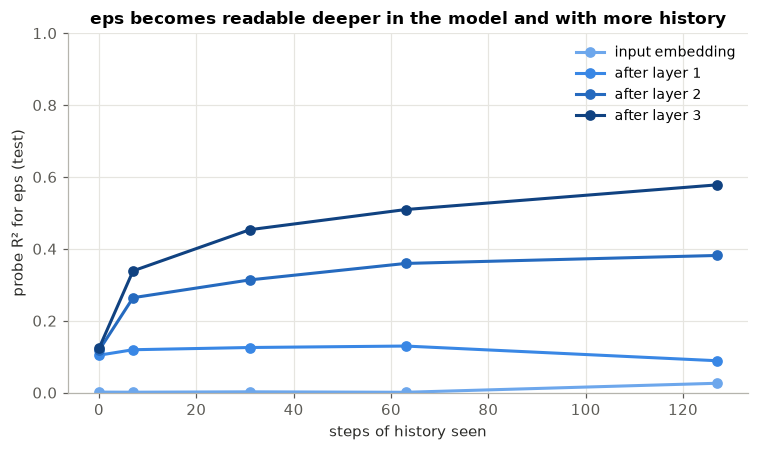

In [3]:
PROBE_POSITIONS = [0, 7, 31, 63, 127]
rows = []
for k, stage in enumerate(STAGES):
    row = {"stage": stage}
    for t in PROBE_POSITIONS:
        readout = ridge_fit(val["hidden"][k][:, t].astype(np.float64), val["eps"].astype(np.float64))
        row[f"t={t}"] = r2(test["eps"], readout(test["hidden"][k][:, t].astype(np.float64)))
    rows.append(row)
probe_table = pd.DataFrame(rows).set_index("stage")
print("probe R² on test windows (1 = perfect, 0 = no better than the average):")
print(probe_table.round(3))

fig, ax = plt.subplots(figsize=(7, 4.2))
for stage, color in zip(STAGES, RAMP[1:]):
    ax.plot(PROBE_POSITIONS, probe_table.loc[stage].values, "-o", color=color, label=stage)
ax.set(xlabel="steps of history seen", ylabel="probe R² for eps (test)", ylim=(0, 1),
       title="eps becomes readable deeper in the model and with more history")
ax.legend()
plt.tight_layout()
plt.show()

**Analysis.** Recorded R²:

| stage | t=0 | t=7 | t=31 | t=63 | t=127 |
|---|---|---|---|---|---|
| input embedding | 0.001 | 0.001 | 0.003 | 0.001 | 0.026 |
| after layer 1 | 0.093 | 0.101 | 0.153 | 0.132 | 0.149 |
| after layer 2 | 0.110 | 0.259 | 0.327 | 0.364 | 0.381 |
| after layer 3 | 0.124 | 0.369 | 0.475 | 0.523 | 0.581 |

Nothing at the input, as expected (eps is never an input). Layer 1 mostly carries the t=0 state leak. Layers 2 and 3 build the estimate up as history arrives, the same shape as the output reading in notebook 06.

## 3. Ceiling, window-level probes and a simple eps direction

In [4]:
out_test = implied_eps_windows(test["probs"], test["states"])
ok = ~np.isnan(out_test)
ceiling = np.corrcoef(test["eps"][ok], out_test[ok])[0, 1] ** 2
print(f"ceiling: model B's own output vs true eps, corr² = {ceiling:.3f}\n")

LOW, HIGH = [0.1, 0.2, 0.3], [0.7, 0.8, 0.9]           # eps 1.0 left out on purpose
rows, proj_by_stage = [], {}
for k, stage in enumerate(STAGES):
    Zv = val["hidden"][k][:, LATE].astype(np.float64).mean(axis=1)    # one vector per window
    Zt = test["hidden"][k][:, LATE].astype(np.float64).mean(axis=1)
    Zv2 = np.concatenate([Zv, (val["hidden"][k][:, LATE].astype(np.float64) ** 2).mean(axis=1)], axis=1)
    Zt2 = np.concatenate([Zt, (test["hidden"][k][:, LATE].astype(np.float64) ** 2).mean(axis=1)], axis=1)

    low = Zv[np.isclose(val["eps"][:, None], LOW).any(axis=1)].mean(0)
    high = Zv[np.isclose(val["eps"][:, None], HIGH).any(axis=1)].mean(0)
    direction = (high - low) / np.linalg.norm(high - low)
    proj = (Zt - (high + low) / 2) @ direction                       # single test windows
    means = np.array([proj[np.isclose(test["eps"], e)].mean() for e in EPS_GRID])
    proj_by_stage[stage] = proj

    rows.append(dict(stage=stage,
                     linear_probe_corr2=np.corrcoef(test["eps"], ridge_fit(Zv, val["eps"])(Zt))[0, 1] ** 2,
                     with_squares_corr2=np.corrcoef(test["eps"], ridge_fit(Zv2, val["eps"])(Zt2))[0, 1] ** 2,
                     direction_corr=np.corrcoef(test["eps"], proj)[0, 1],
                     order_kept_eps_01_09=pd.Series(means[:-1]).rank().corr(pd.Series(EPS_GRID[:-1]).rank())))
window_table = pd.DataFrame(rows).set_index("stage")
print(window_table.round(3))

ceiling: model B's own output vs true eps, corr² = 0.904

                 linear_probe_corr2  with_squares_corr2  direction_corr  \
stage                                                                     
input embedding               0.000               0.145           0.189   
after layer 1                 0.371               0.384           0.233   
after layer 2                 0.538               0.516           0.523   
after layer 3                 0.581               0.587           0.570   

                 order_kept_eps_01_09  
stage                                  
input embedding                 0.200  
after layer 1                   0.683  
after layer 2                   1.000  
after layer 3                   1.000  


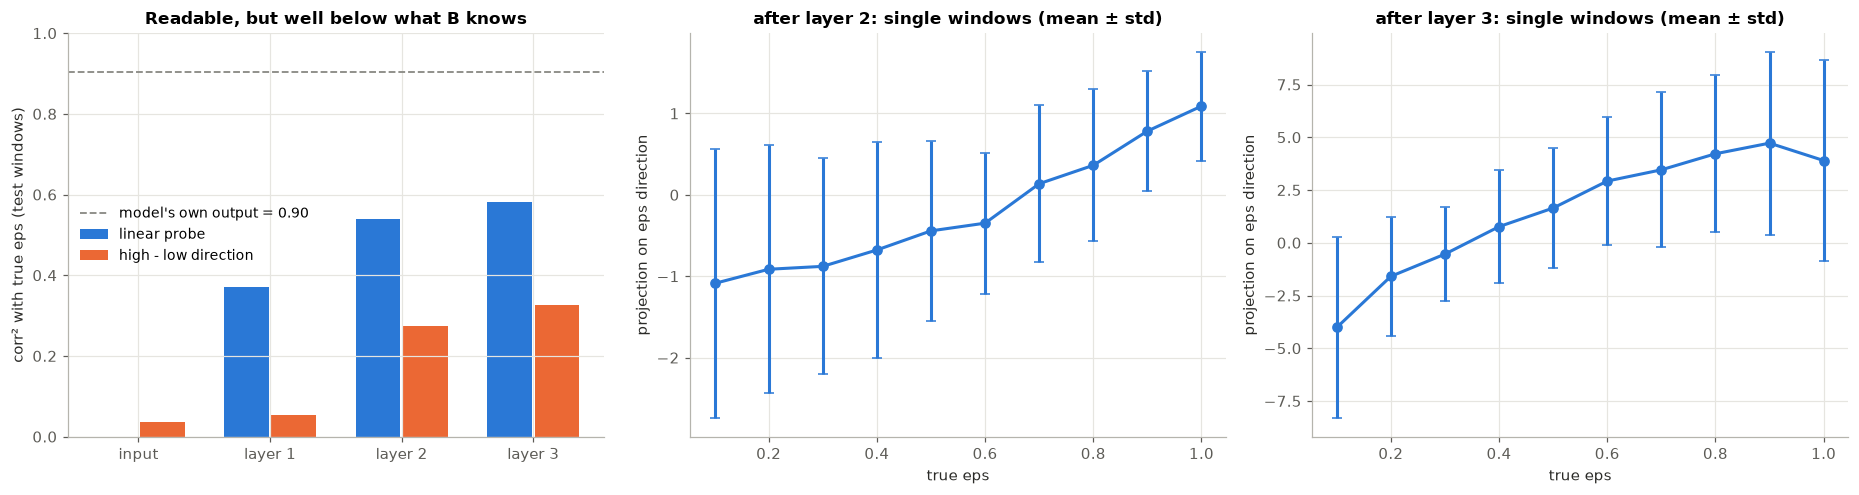

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
ax = axes[0]
x = np.arange(len(STAGES))
ax.bar(x - 0.18, window_table.linear_probe_corr2, width=0.34, color=C["blue"], label="linear probe")
ax.bar(x + 0.18, window_table.direction_corr ** 2, width=0.34, color=C["orange"], label="high - low direction")
ax.axhline(ceiling, color=C["gray"], ls="--", lw=1.2, label=f"model's own output = {ceiling:.2f}")
ax.set_xticks(x, ["input", "layer 1", "layer 2", "layer 3"])
ax.set(ylabel="corr² with true eps (test windows)", ylim=(0, 1), title="Readable, but well below what B knows")
ax.legend()

for ax, stage in zip(axes[1:], ["after layer 2", "after layer 3"]):
    proj = proj_by_stage[stage]
    m = [proj[np.isclose(test["eps"], e)].mean() for e in EPS_GRID]
    sd = [proj[np.isclose(test["eps"], e)].std() for e in EPS_GRID]
    ax.errorbar(EPS_GRID, m, yerr=sd, marker="o", capsize=3, color=C["blue"])
    ax.set(xlabel="true eps", ylabel="projection on eps direction",
           title=f"{stage}: single windows (mean ± std)")
plt.tight_layout()
plt.show()

**Analysis.** Recorded:

| stage | linear probe corr² | with squares | direction corr | eps order kept (0.1 to 0.9) |
|---|---|---|---|---|
| input embedding | 0.000 | 0.133 | 0.179 | 0.25 |
| after layer 1 | 0.383 | 0.395 | 0.263 | 0.95 |
| after layer 2 | 0.516 | 0.507 | 0.467 | 1.00 |
| after layer 3 | 0.579 | 0.569 | 0.642 | 1.00 |

Ceiling (B's output) is 0.899. In layers 2 and 3 a single high-minus-low direction orders eps 0.1 to 0.9 perfectly on average, but individual windows scatter widely around their means (error bars), and the best linear readout reaches only about 0.58. Squared features do not close the gap, so the missing part is not a simple quadratic either.

## 4. Do the per-eps averages lie on one straight line?

In [6]:
summary, means_all = [], []
for k, stage in enumerate(STAGES):
    means = eps_means(val["hidden"][k], val["eps"])                  # eps -> average vector (val)
    M = np.stack([means[round(float(e), 1)] for e in EPS_GRID])        # (10, 64)
    _, S, Vt = np.linalg.svd(M - M.mean(0), full_matrices=False)
    coord = (M - M.mean(0)) @ Vt[0]
    if np.corrcoef(EPS_GRID, coord)[0, 1] < 0:                         # make "more random" = positive
        coord = -coord
    steps = np.diff(M, axis=0)                                         # eps -> eps + 0.1
    cos = [steps[i] @ steps[i + 1] / (np.linalg.norm(steps[i]) * np.linalg.norm(steps[i + 1]))
           for i in range(len(steps) - 1)]
    summary.append(dict(stage=stage, pc1_share=S[0] ** 2 / (S ** 2).sum(),
                        eps_order_kept=pd.Series(coord).rank().corr(pd.Series(EPS_GRID).rank()),
                        step_alignment=float(np.mean(cos))))
    means_all.append(M)
print(pd.DataFrame(summary).set_index("stage").round(3))

np.savez(OUT_DIR / "q2_eps_vectors.npz", eps_grid=EPS_GRID, stages=np.array(STAGES), means=np.stack(means_all))
print("saved", OUT_DIR / "q2_eps_vectors.npz", "(used for injection in notebooks 08 and 10)")

                 pc1_share  eps_order_kept  step_alignment
stage                                                     
input embedding      0.859           0.709          -0.388
after layer 1        0.908           0.745          -0.361
after layer 2        0.769           0.879          -0.318
after layer 3        0.851           0.879          -0.010
saved /home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim/data/eps_models_v2/q2_eps_vectors.npz (used for injection in notebooks 08 and 10)


**Analysis.** Recorded: PC1 explains 0.81 to 0.91 of the spread between the ten averages, but their order along PC1 is imperfect (rank correlation 0.75 to 0.88), and the step from one eps to the next points in inconsistent directions (average alignment -0.41 to 0.16, where 1 would mean a straight line). So eps is not one clean axis; the averages bend through the space. This is why notebook 08 builds a vector for **each pair** of eps values (target average minus source average) instead of using one fixed direction.